# Sprint 13 — Project: Gold Recovery

## Introduction

This project analyzes an industrial process for extracting and purifying gold from ore.

The main objective is to develop machine learning models capable of predicting gold recovery at two stages of the process:

- rougher concentrate recovery (`rougher.output.recovery`);
- final concentrate recovery (`final.output.recovery`).

To achieve this, the data will be explored and prepared, the quality of the available features will be checked, and the characteristics of the process will be examined.

Different regression models will then be trained and evaluated using cross-validation and the sMAPE metric. Finally, the best-performing model will be selected and evaluated on the test set.

## 1. Data Preparation

In this section, the training, test, and full datasets will be loaded. An initial inspection will be performed to understand their structure, size, data types, and missing values.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, make_scorer
from scipy.stats import ks_2samp
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

### 1.1 Loading the Data

We will load the three datasets provided for the project: the training set, the test set, and the full dataset, which contains all available information.

In [69]:
train = pd.read_csv('/datasets/gold_recovery_train.csv')
test = pd.read_csv('/datasets/gold_recovery_test.csv')
full = pd.read_csv('/datasets/gold_recovery_full.csv')

### Initial Dataset Exploration

First, we will check the size of each dataset and display the first rows to understand its structure.

In [70]:
print('Tamaño del conjunto de entrenamiento:', train.shape)
print('Tamaño del conjunto de prueba:', test.shape)
print('Tamaño del conjunto fuente:', full.shape)

display(train.head())

Tamaño del conjunto de entrenamiento: (16860, 87)
Tamaño del conjunto de prueba: (5856, 53)
Tamaño del conjunto fuente: (22716, 87)


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2,2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
3,2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
4,2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691


### Data Structure and Data Types

We will check the data types of the columns and the number of missing values in each dataset. This will help identify potential data quality issues before preprocessing.

In [71]:
print('Valores ausentes en el conjunto de entrenamiento:')
print(train.isna().sum().sum())

print('\nValores ausentes en el conjunto de prueba:')
print(test.isna().sum().sum())

print('\nValores ausentes en el conjunto fuente:')
print(full.isna().sum().sum())

Valores ausentes en el conjunto de entrenamiento:
30320

Valores ausentes en el conjunto de prueba:
2360

Valores ausentes en el conjunto fuente:
36587


### Distribution of Missing Values

Next, we will identify the columns containing missing values and calculate both their count and their proportion within each dataset.

In [72]:
missing_train = train.isna().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)

missing_test = test.isna().sum()
missing_test = missing_test[missing_test > 0].sort_values(ascending=False)

print('Columnas con valores ausentes en el conjunto de entrenamiento:')
display(pd.DataFrame({
    'missing_values': missing_train,
    'missing_percentage': (missing_train / len(train) * 100).round(2)
}))

print('\nColumnas con valores ausentes en el conjunto de prueba:')
display(pd.DataFrame({
    'missing_values': missing_test,
    'missing_percentage': (missing_test / len(test) * 100).round(2)
}))

Columnas con valores ausentes en el conjunto de entrenamiento:


,missing_values,missing_percentage
rougher.output.recovery,2573,15.26
rougher.output.tail_ag,2250,13.35
rougher.output.tail_au,2249,13.34
rougher.output.tail_sol,2249,13.34
secondary_cleaner.output.tail_sol,1986,11.78
...,...,...
primary_cleaner.state.floatbank8_b_level,27,0.16
primary_cleaner.state.floatbank8_c_level,27,0.16
primary_cleaner.state.floatbank8_d_level,27,0.16
rougher.calculation.sulfate_to_au_concentrate,27,0.16



Columnas con valores ausentes en el conjunto de prueba:


,missing_values,missing_percentage
rougher.input.floatbank11_xanthate,353,6.03
primary_cleaner.input.sulfate,302,5.16
primary_cleaner.input.depressant,284,4.85
rougher.input.floatbank10_sulfate,257,4.39
primary_cleaner.input.xanthate,166,2.83
rougher.input.floatbank10_xanthate,123,2.10
rougher.input.feed_sol,67,1.14
rougher.input.floatbank11_sulfate,55,0.94
rougher.input.feed_rate,40,0.68
secondary_cleaner.state.floatbank3_a_air,34,0.58


### 1.2 Checking the Recovery Calculation

Gold recovery in the rougher stage is calculated using the gold concentration in the feed, the concentrate, and the tailings.

We will independently calculate `rougher.output.recovery` using the recovery formula and compare our results with the values provided in the training set.

The difference between the two values will be evaluated using the mean absolute error (MAE).

In [73]:
C = train['rougher.output.concentrate_au']
F = train['rougher.input.feed_au']
T = train['rougher.output.tail_au']
recovery = train['rougher.output.recovery']

valid_rows = C.notna() & F.notna() & T.notna() & recovery.notna()

recovery_calculated = (
    C[valid_rows] * (F[valid_rows] - T[valid_rows])
    / (F[valid_rows] * (C[valid_rows] - T[valid_rows]))
    * 100
)

recovery_mae = mean_absolute_error(
    recovery[valid_rows],
    recovery_calculated
)

print(f'EAM entre la recuperación calculada y la proporcionada: {recovery_mae:.6f}')

EAM entre la recuperación calculada y la proporcionada: 0.000000


### 1.3 Features Not Available in the Test Set

The training set contains features that are not available in the test set. These features correspond to parameters measured or calculated after the point at which a prediction is made.

We will identify these features and examine their types based on the structure of their names.

In [74]:
missing_in_test = train.columns.difference(test.columns)

print(f'Número de características presentes en train pero ausentes en test: {len(missing_in_test)}')
print('\nCaracterísticas ausentes en el conjunto de prueba:')

for feature in missing_in_test:
    print(feature)

Número de características presentes en train pero ausentes en test: 34

Características ausentes en el conjunto de prueba:
final.output.concentrate_ag
final.output.concentrate_au
final.output.concentrate_pb
final.output.concentrate_sol
final.output.recovery
final.output.tail_ag
final.output.tail_au
final.output.tail_pb
final.output.tail_sol
primary_cleaner.output.concentrate_ag
primary_cleaner.output.concentrate_au
primary_cleaner.output.concentrate_pb
primary_cleaner.output.concentrate_sol
primary_cleaner.output.tail_ag
primary_cleaner.output.tail_au
primary_cleaner.output.tail_pb
primary_cleaner.output.tail_sol
rougher.calculation.au_pb_ratio
rougher.calculation.floatbank10_sulfate_to_au_feed
rougher.calculation.floatbank11_sulfate_to_au_feed
rougher.calculation.sulfate_to_au_concentrate
rougher.output.concentrate_ag
rougher.output.concentrate_au
rougher.output.concentrate_pb
rougher.output.concentrate_sol
rougher.output.recovery
rougher.output.tail_ag
rougher.output.tail_au
rougher.

### Classification of Unavailable Features

We will classify the features missing from the test set by type: `input`, `output`, `state`, and `calculation`.

This classification will help us understand why these features cannot be used as input variables for the model.

In [75]:
feature_types = {}

for feature in missing_in_test:
    parts = feature.split('.')
    feature_type = parts[1]
    feature_types[feature] = feature_type

feature_types_df = pd.DataFrame(
    list(feature_types.items()),
    columns=['feature', 'type']
)

display(feature_types_df['type'].value_counts().to_frame('count'))
display(feature_types_df)

,count
output,30
calculation,4


,feature,type
0,final.output.concentrate_ag,output
1,final.output.concentrate_au,output
2,final.output.concentrate_pb,output
3,final.output.concentrate_sol,output
4,final.output.recovery,output
5,final.output.tail_ag,output
6,final.output.tail_au,output
7,final.output.tail_pb,output
8,final.output.tail_sol,output
9,primary_cleaner.output.concentrate_ag,output


### 1.4 Checking the Data Structure

Since the measurements follow a time sequence, we will first check the dates and look for possible duplicates. Chronological order is important for handling missing values later, because measurements taken close together in time may have similar values.

In [76]:
# Convertir las fechas al formato datetime
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])
full['date'] = pd.to_datetime(full['date'])

print('Duplicados en train:', train.duplicated().sum())
print('Duplicados en test:', test.duplicated().sum())
print('Duplicados en full:', full.duplicated().sum())

print('\nFechas únicas:')
print('train:', train['date'].nunique(), 'de', len(train))
print('test:', test['date'].nunique(), 'de', len(test))
print('full:', full['date'].nunique(), 'de', len(full))

print('\nPeríodo de los datos:')
print('train:', train['date'].min(), 'hasta', train['date'].max())
print('test:', test['date'].min(), 'hasta', test['date'].max())
print('full:', full['date'].min(), 'hasta', full['date'].max())

Duplicados en train: 0
Duplicados en test: 0
Duplicados en full: 0

Fechas únicas:
train: 16860 de 16860
test: 5856 de 5856
full: 22716 de 22716

Período de los datos:
train: 2016-01-15 00:00:00 hasta 2018-08-18 10:59:59
test: 2016-09-01 00:59:59 hasta 2017-12-31 23:59:59
full: 2016-01-15 00:00:00 hasta 2018-08-18 10:59:59


### Handling Missing Values

The data contains missing values in several features. Since measurements are taken in a time sequence and values close together in time are often similar, we will use the previous available measurement to fill missing values.

Before applying this treatment, we will sort the data chronologically and check whether any missing values remain at the beginning of each dataset.

In [77]:
# Ordenar los conjuntos de datos cronológicamente
train = train.sort_values('date').reset_index(drop=True)
test = test.sort_values('date').reset_index(drop=True)
full = full.sort_values('date').reset_index(drop=True)

# Completar los valores ausentes utilizando el valor anterior
train_ffill = train.ffill()
test_ffill = test.ffill()
full_ffill = full.ffill()

print('Valores ausentes después de aplicar forward fill:')
print('train:', train_ffill.isna().sum().sum())
print('test:', test_ffill.isna().sum().sum())
print('full:', full_ffill.isna().sum().sum())

Valores ausentes después de aplicar forward fill:
train: 0
test: 0
full: 0


### Applying Preprocessing

The `forward fill` method was used to fill missing values in the datasets used for exploratory analysis and anomaly identification. Since no missing values remain in these datasets, we can continue with the data analysis.

For final model development, the original data will be used again. Missing feature values will be handled within a `Pipeline` using the median calculated exclusively from the training data in each cross-validation fold. This prevents data leakage during model evaluation.

In [78]:
# Utilizar los conjuntos de datos preprocesados
train = train_ffill
test = test_ffill
full = full_ffill

print('Valores ausentes finales:')
print('train:', train.isna().sum().sum())
print('test:', test.isna().sum().sum())
print('full:', full.isna().sum().sum())

Valores ausentes finales:
train: 0
test: 0
full: 0


## 2. Data Analysis

In this section, we will analyze how the concentrations of the main metals change during the different stages of the purification process.

We will examine the concentrations of gold (`Au`), silver (`Ag`), and lead (`Pb`) at three points in the process:

- ore feed;
- concentrate after the rougher stage;
- final concentrate.

### 2.1 Metal Concentrations

First, we will calculate the average concentrations of `Au`, `Ag`, and `Pb` in the ore feed, the rougher concentrate, and the final concentrate.

This will show how the composition of the ore changes during the purification process.

In [79]:
# Calcular la concentración media de cada metal en cada etapa
concentration_means = pd.DataFrame({
    'Alimentación': [
        train['rougher.input.feed_au'].mean(),
        train['rougher.input.feed_ag'].mean(),
        train['rougher.input.feed_pb'].mean()
    ],
    'Concentrado rougher': [
        train['rougher.output.concentrate_au'].mean(),
        train['rougher.output.concentrate_ag'].mean(),
        train['rougher.output.concentrate_pb'].mean()
    ],
    'Concentrado final': [
        train['final.output.concentrate_au'].mean(),
        train['final.output.concentrate_ag'].mean(),
        train['final.output.concentrate_pb'].mean()
    ]
}, index=['Au', 'Ag', 'Pb'])

display(concentration_means)

,Alimentación,Concentrado rougher,Concentrado final
Au,7.144279,17.337662,39.321631
Ag,7.803825,10.541930,4.699066
Pb,3.188803,6.861249,9.080638


### Distribution of Metal Concentrations

In addition to average concentrations, we will analyze the distribution of values using box plots. This will allow us to compare the concentrations of `Au`, `Ag`, and `Pb` in the feed, rougher concentrate, and final concentrate, as well as identify potential outliers.

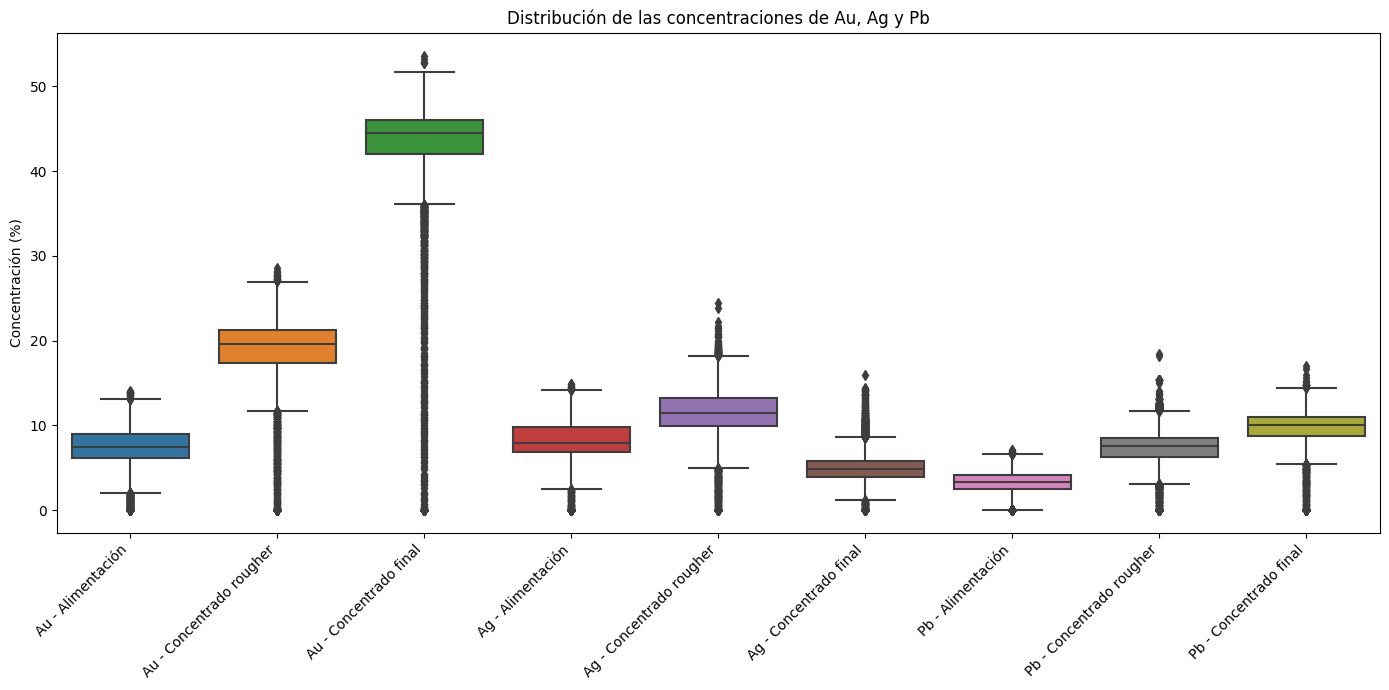

In [80]:
# Preparar los datos para el análisis de las distribuciones
concentration_data = pd.DataFrame({
    'Au - Alimentación': train['rougher.input.feed_au'],
    'Au - Concentrado rougher': train['rougher.output.concentrate_au'],
    'Au - Concentrado final': train['final.output.concentrate_au'],
    'Ag - Alimentación': train['rougher.input.feed_ag'],
    'Ag - Concentrado rougher': train['rougher.output.concentrate_ag'],
    'Ag - Concentrado final': train['final.output.concentrate_ag'],
    'Pb - Alimentación': train['rougher.input.feed_pb'],
    'Pb - Concentrado rougher': train['rougher.output.concentrate_pb'],
    'Pb - Concentrado final': train['final.output.concentrate_pb']
})

plt.figure(figsize=(14, 7))
sns.boxplot(data=concentration_data)
plt.title('Distribución de las concentraciones de Au, Ag y Pb')
plt.ylabel('Concentración (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Results of the Concentration Analysis

The concentration of gold increases considerably during the purification process. Its average value rises from approximately 7.14% in the feed to 17.34% in the rougher concentrate and reaches 39.32% in the final concentrate.

The concentration of silver initially increases during the rougher stage but decreases in the final concentrate. Lead concentration increases progressively throughout the stages analyzed.

The box plots also show numerous outliers, especially in the concentrates. These values will not be removed yet, because the next section examines the total concentrations of the substances to determine which observations represent anomalies that should be removed.

### 2.2 Particle Size Distribution

Before building the models, we need to check whether the particle size distribution in the feed is similar in the training and test sets.

The feature used for this comparison is `rougher.input.feed_size`. A substantial difference between the distributions could affect model evaluation, since the test set should represent conditions similar to those used during training.

In [81]:
# Comparar la distribución del tamaño de las partículas
particle_size = pd.DataFrame({
    'Train': train['rougher.input.feed_size'],
    'Test': test['rougher.input.feed_size']
})

display(particle_size.describe().round(2))

,Train,Test
count,16860.00,5856.00
mean,60.19,55.90
std,30.52,22.71
min,9.66,0.05
25%,47.55,43.85
50%,54.07,49.96
75%,65.40,61.63
max,484.97,477.45


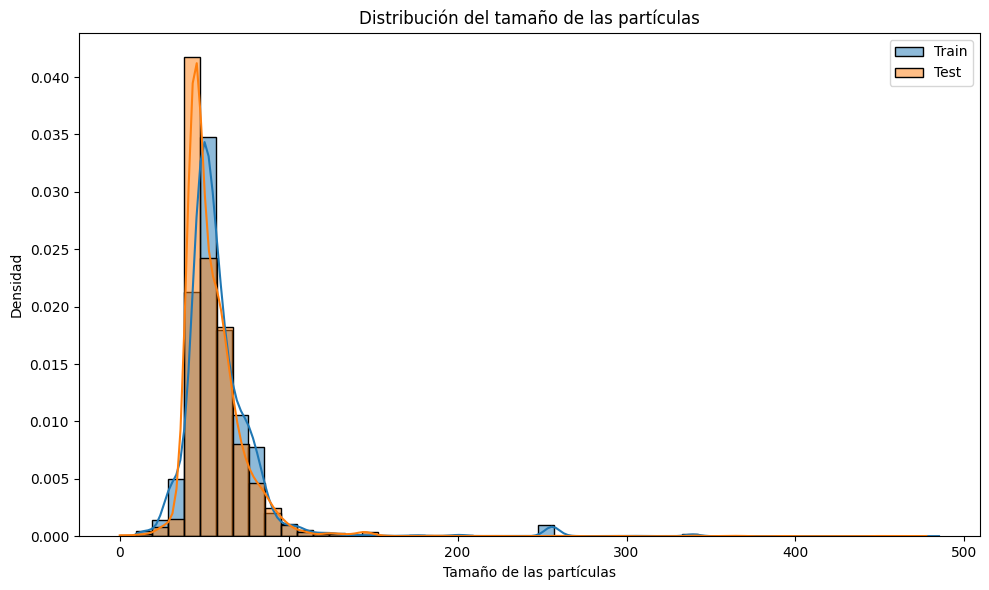

In [82]:
# Comparar visualmente las distribuciones del tamaño de las partículas
plt.figure(figsize=(10, 6))

sns.histplot(
    train['rougher.input.feed_size'],
    bins=50,
    stat='density',
    kde=True,
    color='tab:blue',
    label='Train',
    alpha=0.5
)

sns.histplot(
    test['rougher.input.feed_size'],
    bins=50,
    stat='density',
    kde=True,
    color='tab:orange',
    label='Test',
    alpha=0.5
)

plt.title('Distribución del tamaño de las partículas')
plt.xlabel('Tamaño de las partículas')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()
plt.show()

### Statistical Test of the Distributions

To complement the visual comparison, we will apply the Kolmogorov-Smirnov test. This test checks whether the particle size distributions in the training and test sets differ statistically significantly.

The null hypothesis states that both samples come from the same distribution.

In [83]:
# Aplicar la prueba de Kolmogorov-Smirnov
ks_statistic, ks_pvalue = ks_2samp(
    train['rougher.input.feed_size'],
    test['rougher.input.feed_size']
)

print(f'Estadístico KS: {ks_statistic:.4f}')
print(f'Valor p: {ks_pvalue:.6f}')

Estadístico KS: 0.1880
Valor p: 0.000000


### Results of the Particle Size Comparison

The descriptive statistics and distribution plot show that the training and test sets have a similar overall shape, although there are some differences in their central values and spread.

The Kolmogorov-Smirnov test produced a statistic of 0.1880 and a p-value below 0.001. Therefore, we reject the null hypothesis that both samples come from the same distribution.

This indicates a statistically significant difference between the particle size distributions of the training and test sets. However, the distributions retain a comparable overall shape, so this difference should be considered when interpreting the model evaluation results.

### 2.3 Total Concentration and Anomalies

To identify anomalous values, we will calculate the total concentration of the main substances at three points in the process:

- ore feed;
- rougher concentrate;
- final concentrate.

Total concentration will be calculated as the sum of `Au`, `Ag`, `Pb`, and `Sol`.

We will first analyze the distributions of these concentrations. We will then determine which values should be considered anomalous and remove the corresponding rows from the training and test sets.

In [84]:
# Calcular la concentración total de las sustancias en cada etapa
train['total_feed_concentration'] = (
    train['rougher.input.feed_au']
    + train['rougher.input.feed_ag']
    + train['rougher.input.feed_pb']
    + train['rougher.input.feed_sol']
)

train['total_rougher_concentration'] = (
    train['rougher.output.concentrate_au']
    + train['rougher.output.concentrate_ag']
    + train['rougher.output.concentrate_pb']
    + train['rougher.output.concentrate_sol']
)

train['total_final_concentration'] = (
    train['final.output.concentrate_au']
    + train['final.output.concentrate_ag']
    + train['final.output.concentrate_pb']
    + train['final.output.concentrate_sol']
)

display(
    train[
        [
            'total_feed_concentration',
            'total_rougher_concentration',
            'total_final_concentration'
        ]
    ].describe().round(2)
)

,total_feed_concentration,total_rougher_concentration,total_final_concentration
count,16860.00,16860.00,16860.00
mean,50.44,59.96,61.27
std,18.18,24.04,21.69
min,0.00,0.00,0.00
25%,50.29,61.47,66.53
50%,55.79,68.33,68.80
75%,60.26,73.02,70.70
max,76.02,90.96,80.21


### Distribution of Total Concentration

We will visually analyze the distribution of total concentration in the feed, rougher concentrate, and final concentrate.

Values close to zero are particularly important, since a total concentration of zero is not physically plausible for an ore sample.

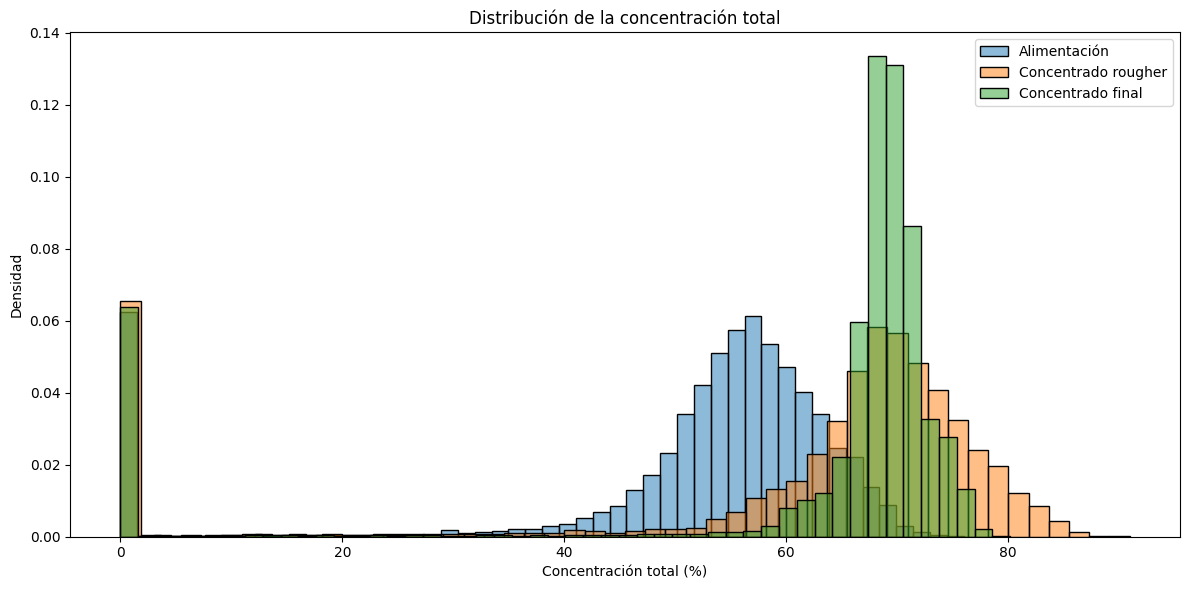

In [85]:
plt.figure(figsize=(12, 6))

sns.histplot(
    train['total_feed_concentration'],
    bins=50,
    stat='density',
    color='tab:blue',
    label='Alimentación',
    alpha=0.5
)

sns.histplot(
    train['total_rougher_concentration'],
    bins=50,
    stat='density',
    color='tab:orange',
    label='Concentrado rougher',
    alpha=0.5
)

sns.histplot(
    train['total_final_concentration'],
    bins=50,
    stat='density',
    color='tab:green',
    label='Concentrado final',
    alpha=0.5
)

plt.title('Distribución de la concentración total')
plt.xlabel('Concentración total (%)')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()
plt.show()

In [86]:
# Contar los valores de concentración total iguales a cero
zero_concentrations = pd.DataFrame({
    'Alimentación': (train['total_feed_concentration'] == 0).sum(),
    'Concentrado rougher': (train['total_rougher_concentration'] == 0).sum(),
    'Concentrado final': (train['total_final_concentration'] == 0).sum()
}, index=['Cantidad de valores iguales a cero'])

display(zero_concentrations)

,Alimentación,Concentrado rougher,Concentrado final
Cantidad de valores iguales a cero,1213,1547,1320


### Identifying Anomalous Rows

Rows with a total concentration equal to zero are not physically plausible and must be removed before training the models.

Since some rows may have a total concentration of zero at more than one stage, we will not simply add the counts from the previous stages. Instead, we will identify each row individually.

For the test set, we will use the `full` source dataset, which contains the output features that are not available in `test`. The unique dates allow us to match the rows in `test` correctly with their corresponding data in `full`.

In [87]:
# Calcular las concentraciones totales en el conjunto fuente
full['total_feed_concentration'] = (
    full['rougher.input.feed_au']
    + full['rougher.input.feed_ag']
    + full['rougher.input.feed_pb']
    + full['rougher.input.feed_sol']
)

full['total_rougher_concentration'] = (
    full['rougher.output.concentrate_au']
    + full['rougher.output.concentrate_ag']
    + full['rougher.output.concentrate_pb']
    + full['rougher.output.concentrate_sol']
)

full['total_final_concentration'] = (
    full['final.output.concentrate_au']
    + full['final.output.concentrate_ag']
    + full['final.output.concentrate_pb']
    + full['final.output.concentrate_sol']
)

# Identificar filas anómalas en el conjunto de entrenamiento
train_anomalous_dates = train.loc[
    (train['total_feed_concentration'] == 0)
    | (train['total_rougher_concentration'] == 0)
    | (train['total_final_concentration'] == 0),
    'date'
]

# Identificar las mismas anomalías en el conjunto de prueba mediante full
test_full = full[full['date'].isin(test['date'])]

test_anomalous_dates = test_full.loc[
    (test_full['total_feed_concentration'] == 0)
    | (test_full['total_rougher_concentration'] == 0)
    | (test_full['total_final_concentration'] == 0),
    'date'
]

print('Filas anómalas en train:', len(train_anomalous_dates))
print('Filas anómalas en test:', len(test_anomalous_dates))

Filas anómalas en train: 1732
Filas anómalas en test: 564


In [88]:
# Verificar que todas las filas de test estén presentes en full
test_dates_in_full = full['date'].isin(test['date']).sum()

print('Filas de test:', len(test))
print('Filas de test encontradas en full:', test_dates_in_full)
print('Fechas de test no encontradas en full:', len(test) - test_dates_in_full)

Filas de test: 5856
Filas de test encontradas en full: 5856
Fechas de test no encontradas en full: 0


### Removing Anomalous Rows

Rows with a total concentration equal to zero are considered anomalous and will be removed from the training and test sets.

The same observations will be removed based on their dates, avoiding the use of features that are not directly available in the test set.

In [89]:
# Eliminar las filas anómalas de los conjuntos de entrenamiento y prueba
train = train[~train['date'].isin(train_anomalous_dates)].copy()
test = test[~test['date'].isin(test_anomalous_dates)].copy()

# Restablecer los índices
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

print('Tamaño de train después de eliminar anomalías:', train.shape)
print('Tamaño de test después de eliminar anomalías:', test.shape)

Tamaño de train después de eliminar anomalías: (15128, 90)
Tamaño de test después de eliminar anomalías: (5292, 53)


In [90]:
# Verificar que no queden filas con concentración total igual a cero
remaining_anomalies = pd.DataFrame({
    'Alimentación': (train['total_feed_concentration'] == 0).sum(),
    'Concentrado rougher': (train['total_rougher_concentration'] == 0).sum(),
    'Concentrado final': (train['total_final_concentration'] == 0).sum()
}, index=['Valores iguales a cero'])

display(remaining_anomalies)

,Alimentación,Concentrado rougher,Concentrado final
Valores iguales a cero,0,0,0


## 3. Model Development

The objective of this project is to predict gold recovery at two stages of the process:

- `rougher.output.recovery`;
- `final.output.recovery`.

These target variables are not available in the test set. For this reason, we will use the original `full` dataset to obtain the corresponding actual values for the dates in the test set.

The relationship between `test` and `full` will be established using the `date` column, which contains unique values for each observation.

In [91]:
# Definir las variables objetivo
target_rougher = 'rougher.output.recovery'
target_final = 'final.output.recovery'

# Obtener los valores reales de las variables objetivo para las filas de test
test_targets = full[
    full['date'].isin(test['date'])
][['date', target_rougher, target_final]]

# Mantener únicamente las fechas que permanecen en el conjunto de test
test_targets = test[['date']].merge(
    test_targets,
    on='date',
    how='left',
    validate='one_to_one'
)

print('Filas de test:', len(test))
print('Filas con objetivo rougher:', test_targets[target_rougher].notna().sum())
print('Filas con objetivo final:', test_targets[target_final].notna().sum())

Filas de test: 5292
Filas con objetivo rougher: 5292
Filas con objetivo final: 5292


### Preparing the Model Features

For model training, we will use only the features available in both the training and test sets.

We will not use:

- the `date` column, because it represents the measurement time rather than a numerical process variable;
- the two target variables;
- features that are not available in the test set;
- the auxiliary total-concentration columns used only for anomaly analysis.

This ensures that the features used during training will also be available when the model makes predictions on new data.

In [92]:
# Definir las columnas que no se utilizarán como características
excluded_columns = (
    ['date', target_rougher, target_final]
    + list(missing_in_test)
    + [
        'total_feed_concentration',
        'total_rougher_concentration',
        'total_final_concentration'
    ]
)

# Crear las variables de entrada
features = [column for column in train.columns if column not in excluded_columns]

X = train[features]
y_rougher = train[target_rougher]
y_final = train[target_final]

X_test = test[features]

print('Número de características utilizadas:', len(features))
print('Tamaño de X:', X.shape)
print('Tamaño de X_test:', X_test.shape)

Número de características utilizadas: 52
Tamaño de X: (15128, 52)
Tamaño de X_test: (5292, 52)


### 3.1 sMAPE Function

We will use sMAPE (symmetric Mean Absolute Percentage Error) to evaluate prediction quality.

The metric will be calculated separately for rougher recovery and final recovery.

The model's final score will be a weighted combination of the two metrics:

- 25% for `rougher.output.recovery`;
- 75% for `final.output.recovery`.

A lower sMAPE value indicates better model performance.

In [93]:
# Definir la función sMAPE
def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    
    smape_values = np.where(
        denominator == 0,
        0,
        np.abs(y_true - y_pred) / denominator
    )
    
    return np.mean(smape_values) * 100


# Definir la métrica final ponderada
def final_smape(y_true_rougher, y_pred_rougher, y_true_final, y_pred_final):
    smape_rougher = smape(y_true_rougher, y_pred_rougher)
    smape_final = smape(y_true_final, y_pred_final)
    
    return 0.25 * smape_rougher + 0.75 * smape_final

### 3.2 Preparing the Data for Modeling

To prevent data leakage during cross-validation, we will prepare the data again for the modeling stage.

Missing values in the target variables will not be imputed. Rows without values for `rougher.output.recovery` or `final.output.recovery` will be removed.

Missing feature values will be handled later within the cross-validation process. This ensures that preprocessing uses only the information available in the training data of each fold.

In [94]:
# Volver a cargar los datos originales para el modelado
train_model = pd.read_csv('/datasets/gold_recovery_train.csv')
train_model['date'] = pd.to_datetime(train_model['date'])

# Eliminar las filas anómalas identificadas anteriormente
train_model = train_model[
    ~train_model['date'].isin(train_anomalous_dates)
].copy()

# Eliminar filas sin valores en las variables objetivo
train_model = train_model.dropna(
    subset=[target_rougher, target_final]
).reset_index(drop=True)

# Seleccionar únicamente las características disponibles en test
features_model = [
    column for column in test.columns
    if column != 'date'
]

X_model = train_model[features_model]
y_rougher_model = train_model[target_rougher]
y_final_model = train_model[target_final]

print('Tamaño de X_model:', X_model.shape)
print('Valores ausentes en las características:', X_model.isna().sum().sum())
print('Valores ausentes en y_rougher:', y_rougher_model.isna().sum())
print('Valores ausentes en y_final:', y_final_model.isna().sum())

Tamaño de X_model: (13795, 52)
Valores ausentes en las características: 1575
Valores ausentes en y_rougher: 0
Valores ausentes en y_final: 0


### 3.3 Preprocessing and Cross-Validation

To handle missing values correctly during cross-validation, we will use a `Pipeline`.

In each fold, missing feature values will be replaced with the median calculated exclusively from the data used for training. This prevents information from the validation set from being used during preprocessing.

The models will be evaluated using five-fold cross-validation and the sMAPE metric. The final score will combine rougher recovery sMAPE with a weight of 25% and final recovery sMAPE with a weight of 75%.

In [95]:
# Configurar la validación cruzada
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Crear el evaluador sMAPE
smape_scorer = make_scorer(
    smape,
    greater_is_better=False
)


def create_pipeline(model):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', model)
    ])


def evaluate_model(model):
    # Crear una nueva pipeline para cada variable objetivo
    rougher_pipeline = create_pipeline(model)
    final_pipeline = create_pipeline(model)

    # Evaluar la recuperación rougher
    rougher_scores = -cross_val_score(
        rougher_pipeline,
        X_model,
        y_rougher_model,
        cv=cv,
        scoring=smape_scorer,
        n_jobs=-1
    )

    # Evaluar la recuperación final
    final_scores = -cross_val_score(
        final_pipeline,
        X_model,
        y_final_model,
        cv=cv,
        scoring=smape_scorer,
        n_jobs=-1
    )

    # Calcular el sMAPE final ponderado
    final_score = (
        0.25 * rougher_scores.mean()
        + 0.75 * final_scores.mean()
    )

    return (
        rougher_scores.mean(),
        final_scores.mean(),
        final_score
    )

### 3.4 Model Comparison

We will compare different regression models to determine which provides the best performance when predicting gold recovery.

We will evaluate linear regression, a decision tree, and a random forest. Different maximum depths will be tested for the tree-based models.

The comparison will use cross-validation, with the weighted final sMAPE as the main selection criterion.

In [97]:
models = {
    'Regresión lineal': LinearRegression(),
    'Árbol de decisión (profundidad 5)': DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),
    'Árbol de decisión (profundidad 10)': DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    'Bosque aleatorio (100 árboles, profundidad 10)': RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    'Bosque aleatorio (100 árboles, profundidad 20)': RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for model_name, model in models.items():
    rougher_score, final_score, total_score = evaluate_model(model)
    
    results.append({
        'Modelo': model_name,
        'sMAPE rougher': rougher_score,
        'sMAPE final': final_score,
        'sMAPE final ponderado': total_score
    })

results_df = pd.DataFrame(results).sort_values(
    'sMAPE final ponderado'
).reset_index(drop=True)

display(results_df.round(2))

,Modelo,sMAPE rougher,sMAPE final,sMAPE final ponderado
0,"Bosque aleatorio (100 árboles, profundidad 20)",2.60,5.84,5.03
1,"Bosque aleatorio (100 árboles, profundidad 10)",3.05,6.55,5.68
2,Árbol de decisión (profundidad 10),3.68,7.52,6.56
3,Árbol de decisión (profundidad 5),4.51,8.03,7.15
4,Regresión lineal,4.69,8.20,7.33


### 3.5 Preparing the Test Set Target Values

For the final evaluation, we will use the actual target values for the test set.

These values will be obtained directly from the original full dataset, without imputation. This ensures that the final evaluation uses observed values rather than values filled in during preprocessing.

In [98]:
### Cargar nuevamente los datos originales

test_model_original = pd.read_csv('/datasets/gold_recovery_test.csv')
test_model_original['date'] = pd.to_datetime(test_model_original['date'])

full_test_original = pd.read_csv('/datasets/gold_recovery_full.csv')
full_test_original['date'] = pd.to_datetime(full_test_original['date'])


# Eliminar las filas anómalas identificadas anteriormente
test_model_original = test_model_original[
    ~test_model_original['date'].isin(test_anomalous_dates)
].copy()


# Obtener los valores objetivo originales desde el conjunto fuente
test_targets = full_test_original[
    full_test_original['date'].isin(test_model_original['date'])
][
    ['date', target_rougher, target_final]
].copy()


# Mantener únicamente las fechas con ambos valores objetivo disponibles
valid_dates = test_targets.loc[
    test_targets[target_rougher].notna()
    & test_targets[target_final].notna(),
    'date'
]


test_model_original = test_model_original[
    test_model_original['date'].isin(valid_dates)
].copy()

test_targets = test_targets[
    test_targets['date'].isin(valid_dates)
].copy()


# Ordenar ambos conjuntos por fecha
test_model_original = test_model_original.sort_values(
    'date'
).reset_index(drop=True)

test_targets = test_targets.sort_values(
    'date'
).reset_index(drop=True)


# Crear las características del conjunto de prueba
X_test_model = test_model_original[features_model]

y_test_rougher = test_targets[target_rougher]
y_test_final = test_targets[target_final]


print('Filas disponibles para la evaluación final:', len(X_test_model))
print('Valores ausentes en las características:', X_test_model.isna().sum().sum())
print('Valores ausentes en y_rougher:', y_test_rougher.isna().sum())
print('Valores ausentes en y_final:', y_test_final.isna().sum())

Filas disponibles para la evaluación final: 5154
Valores ausentes en las características: 66
Valores ausentes en y_rougher: 0
Valores ausentes en y_final: 0


### 3.6 Final Evaluation on the Test Set

The Random Forest with 100 trees and a maximum depth of 20 achieved the best cross-validation result, with a weighted final sMAPE of 5.03.

We will now train this model using all available training data. Missing values will be handled using the same `Pipeline` applied during cross-validation.

Finally, we will evaluate the model using the test observations for which both actual target values are available.

In [99]:
# Crear las pipelines finales
rougher_pipeline = create_pipeline(
    RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )
)

final_pipeline = create_pipeline(
    RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )
)

# Entrenar los modelos con todos los datos de entrenamiento
rougher_pipeline.fit(X_model, y_rougher_model)
final_pipeline.fit(X_model, y_final_model)

# Realizar las predicciones sobre el conjunto de prueba
rougher_predictions = rougher_pipeline.predict(X_test_model)
final_predictions = final_pipeline.predict(X_test_model)

# Calcular las métricas
test_smape_rougher = smape(
    y_test_rougher,
    rougher_predictions
)

test_smape_final = smape(
    y_test_final,
    final_predictions
)

test_final_smape = final_smape(
    y_test_rougher,
    rougher_predictions,
    y_test_final,
    final_predictions
)

print(f'sMAPE rougher en test: {test_smape_rougher:.2f}')
print(f'sMAPE final en test: {test_smape_final:.2f}')
print(f'sMAPE final ponderado en test: {test_final_smape:.2f}')

sMAPE rougher en test: 4.33
sMAPE final en test: 8.14
sMAPE final ponderado en test: 7.19


### 3.7 Comparison with the Baseline Model

To check whether the selected model provides a genuine improvement, we will compare it with a baseline model that always predicts the median of the training data.

The comparison will use the same test observations that were used to evaluate the Random Forest.

A lower sMAPE indicates better performance.

In [100]:
# Crear los modelos de referencia
rougher_baseline = create_pipeline(
    DummyRegressor(strategy='median')
)

final_baseline = create_pipeline(
    DummyRegressor(strategy='median')
)

# Entrenar los modelos de referencia
rougher_baseline.fit(
    X_model,
    y_rougher_model
)

final_baseline.fit(
    X_model,
    y_final_model
)

# Realizar las predicciones
rougher_baseline_predictions = rougher_baseline.predict(
    X_test_model
)

final_baseline_predictions = final_baseline.predict(
    X_test_model
)

# Calcular las métricas
baseline_smape_rougher = smape(
    y_test_rougher,
    rougher_baseline_predictions
)

baseline_smape_final = smape(
    y_test_final,
    final_baseline_predictions
)

baseline_final_smape = final_smape(
    y_test_rougher,
    rougher_baseline_predictions,
    y_test_final,
    final_baseline_predictions
)

print(
    f'sMAPE rougher del modelo de referencia: '
    f'{baseline_smape_rougher:.2f}'
)

print(
    f'sMAPE final del modelo de referencia: '
    f'{baseline_smape_final:.2f}'
)

print(
    f'sMAPE final ponderado del modelo de referencia: '
    f'{baseline_final_smape:.2f}'
)

sMAPE rougher del modelo de referencia: 4.82
sMAPE final del modelo de referencia: 8.21
sMAPE final ponderado del modelo de referencia: 7.36


### 3.8 Final Results

Cross-validation showed that the best model among those evaluated was the Random Forest with 100 trees and a maximum depth of 20.

This model achieved a weighted final sMAPE of 5.03 during cross-validation, compared with 5.68 for the Random Forest with a maximum depth of 10, 6.56 for the Decision Tree with a maximum depth of 10, 7.15 for the Decision Tree with a maximum depth of 5, and 7.33 for Linear Regression.

The selected model was then trained using all available training data and evaluated on the test set. The results were:

- rougher sMAPE: 4.33
- final sMAPE: 8.14
- weighted final sMAPE: 7.19

As an additional check, the model was compared with a baseline model that always predicts the median of the training data. The baseline model achieved a weighted final sMAPE of 7.36.

Therefore, the selected Random Forest performs better than the baseline model, although the difference is moderate. The weighted final sMAPE of 7.19 represents an improvement over predictions based only on the median.